In [5]:
keys = ["name", "age", "city"]
values = ["Tom", "21", "Seoul"]


print(type(zip(keys, values)))
list(zip(keys, values))

<class 'zip'>


[('name', 'Tom'), ('age', '21'), ('city', 'Seoul')]

In [1]:
def test():
    print('hi')
    
test()

hi


In [10]:
def my_add(a, b):
    '''
    정수 a,b를 받으면 a + b를 반환합니다.
    
    Args:
        a(int): 첫 번째 정수
        b(int): 두 번째 정수
        
    Return:
        int: 두 수의 합
    '''
    return a + b
    
print(my_add.__doc__)


    정수 a,b를 받으면 a + b를 반환합니다.
    
    Args:
        a(int): 첫 번째 정수
        b(int): 두 번째 정수
        
    Return:
        int: 두 수의 합
    


In [8]:
my_add(2,3)

5

In [13]:
# 반환값이 있는 경우
# 함수 정의부

def my_add(a,b):
    return a + b # 해당 반환값으로 함수의 호출결과를 치환시켜줌

my_add(1,2)

a = my_add(1,3)
b = my_add(3,5)
a + b

12

In [14]:
# 반환값이 없는 경우

def my_add(a,b):
    return

a = my_add(1,2)
a
print(a)

None


In [16]:
# 반환값이 없는 경우2

def my_add(a,b):
    print(a + b)
    return


my_add(2,3)
print(my_add(2,3))

5
5
None


In [2]:
import pandas as pd

s = pd.Series([9904, 3448, 2890, 2466], index=['서울', '부산', '인천', '대구'])

print(type(s))

<class 'pandas.core.series.Series'>


In [5]:
print(s.index)
print(s.values)

Index(['서울', '부산', '인천', '대구'], dtype='object')
[9904 3448 2890 2466]


In [6]:
s.index.name= '도시'

In [7]:
s

도시
서울    9904
부산    3448
인천    2890
대구    2466
dtype: int64

In [16]:
df = pd.read_csv('./data/score.csv', index_col='과목', encoding='euc-kr')
df

,1반,2반,3반,4반
과목,,,,
수학,45,44,73,39
영어,76,92,45,69
국어,47,92,45,69
사회,92,81,85,40
과학,11,79,47,26


In [17]:
display(df['1반']) # 칼럼에 접근하는 방법 -> series
display(df[:'수학']) # 행에 접근하는 방법 -> dataframe

과목
수학    45
영어    76
국어    47
사회    92
과학    11
Name: 1반, dtype: int64

,1반,2반,3반,4반
과목,,,,
수학,45,44,73,39


## value_counts()
- 특정 칼럼의 각 unique 값의 총 개수 반환
- 범주형 데이터(칼럼)에서 주로 사용됨

In [32]:
df = pd.DataFrame([["집중", "집중", "졸림"],
                        ["집중", "집중", "조는중"],
                        ["집중", "졸림"]],
                        columns=["1교시", "2교시", "3교시"])

In [28]:
display(df['1교시'].unique())
display(df['2교시'].unique())
display(df['3교시'].unique())

display(df['1교시'].nunique())
display(df['2교시'].nunique())
display(df['3교시'].nunique())

array(['집중'], dtype=object)

array(['집중', '졸림'], dtype=object)

array(['졸림', '조는중', None], dtype=object)

1

2

2

In [29]:
display(df['1교시'].value_counts())

1교시
집중    3
Name: count, dtype: int64

### 2.7 fillna()

In [33]:
import copy

df2 = copy.deepcopy(df)

df2

,1교시,2교시,3교시
0,집중,집중,졸림
1,집중,집중,조는중
2,집중,졸림,None


In [34]:
df2.fillna('열심히 할게요')

,1교시,2교시,3교시
0,집중,집중,졸림
1,집중,집중,조는중
2,집중,졸림,열심히 할게요


In [36]:
df2.fillna('열심히 할게요', inplace=True)
df2_1 = df2.fillna('열심히 할게요')

In [38]:
display(df2)
display(df2_1)

,1교시,2교시,3교시
0,집중,집중,졸림
1,집중,집중,조는중
2,집중,졸림,열심히 할게요


,1교시,2교시,3교시
0,집중,집중,졸림
1,집중,집중,조는중
2,집중,졸림,열심히 할게요


In [39]:
df3 = copy.deepcopy(df)
display('결측치 채우기전:', df3)
df3.fillna('열심히 할게요!', inplace=True)
display('결측치 채운 후:', df3)


'결측치 채우기전:'

,1교시,2교시,3교시
0,집중,집중,졸림
1,집중,집중,조는중
2,집중,졸림,None


'결측치 채운 후:'

,1교시,2교시,3교시
0,집중,집중,졸림
1,집중,집중,조는중
2,집중,졸림,열심히 할게요!


## 2.8 dropna()

- 결측치가 포함된 행 삭제



In [40]:
temp = pd.DataFrame([["집중", "집중", "졸림"],
                        [None, "집중", "조는중"],
                        [None, "졸림"]],
                        columns=["1교시", "2교시", "3교시"])

In [43]:
temp['3교시'].fillna('화이팅')

0     졸림
1    조는중
2    화이팅
Name: 3교시, dtype: object

In [44]:
temp.dropna()

,1교시,2교시,3교시
0,집중,집중,졸림


In [51]:
import copy 
df5 = copy.deepcopy(df)

df5.dropna(axis=1)

,1교시,2교시
0,집중,집중
1,집중,집중
2,집중,졸림


## 2.9 apply()

- 행 또는 열 전체에 사용자가 만든 사용자 정의 함수를 한번에 적용시켜주는 함수 
- apply함수 사용을 위해서는 사전에 사용자 정의 함수가 반드시 선언되어 있어야 함 


In [54]:
df = pd.read_csv('./data/score.csv', index_col='과목', encoding='euc-kr')
df

,1반,2반,3반,4반
과목,,,,
수학,45,44,73,39
영어,76,92,45,69
국어,47,92,45,69
사회,92,81,85,40
과학,11,79,47,26


In [55]:
def cal(x):
    return x.max() - x.min()

In [57]:
df.apply(cal, axis=1) # 열 기준 계산

과목
수학    34
영어    47
국어    47
사회    52
과학    68
dtype: int64

In [58]:
df['편차'] = df.apply(cal, axis=1)

In [59]:
df

,1반,2반,3반,4반,편차
과목,,,,,
수학,45,44,73,39,34
영어,76,92,45,69,47
국어,47,92,45,69,47
사회,92,81,85,40,52
과학,11,79,47,26,68


## 2.10 concat()
- Series나 Df 병합할 때 사용
- iterable 객체를 인자로 받음

In [60]:
s1 = pd.Series([1, 2, 3, 4, 5])
s2 = pd.Series(["female", "female", "male", "male", "male", "female"])
s3 = pd.Series(["합", "불", "합", "불", "합"])

In [62]:
pd.concat([s1,s2,s3],axis=1)

,0,1,2
0,1.0,female,합
1,2.0,female,불
2,3.0,male,합
3,4.0,male,불
4,5.0,male,합
5,NaN,female,NaN


## 2.11 groupby()
- 그룹별로 묶어 집계값을 출력할 수 있게 하는 함수
- 데이터를 특정 기준으로 묶은 뒤, 각 그룹에 대해 통계 요약을 수행
- 스프레드시트의 피벗 테이블과 기능 유사

In [63]:
exam = pd.concat([s1,s2,s3], axis=1)
exam.columns = ['ID', 'Gender', 'Result']

exam

,ID,Gender,Result
0,1.0,female,합
1,2.0,female,불
2,3.0,male,합
3,4.0,male,불
4,5.0,male,합
5,NaN,female,NaN


In [65]:
exam.groupby(['Gender', 'Result']).count()

ID
Gender Result    
female 불        1
       합        1
male   불        1
       합        2

In [68]:
exam.groupby(['Gender'])['Result'].value_counts()

Gender  Result
female  불         1
        합         1
male    합         2
        불         1
Name: count, dtype: int64

In [69]:
import pandas as pd

df = pd.DataFrame({
    "반": ["1반", "1반", "2반", "2반"],
    "과목": ["수학", "영어", "수학", "영어"],
    "점수": [80, 75, 90, 85]
})

In [70]:
df

,반,과목,점수
0,1반,수학,80
1,1반,영어,75
2,2반,수학,90
3,2반,영어,85


In [72]:
df.groupby(['반'])['점수'].mean()

반
1반    77.5
2반    87.5
Name: 점수, dtype: float64

# 3. 실습 

2015-2017년도 광주광역시 범죄현황 데이터를 이용해 전년 대비 지역별 범죄 증감율을 구해보세요.

- 증감율 = (금년-작년)/작년*100
    - ex) 2015-2016증감율 = (15416-18830)/18830*100
- 아래 화면과 동일한 결과를 출력해보세요

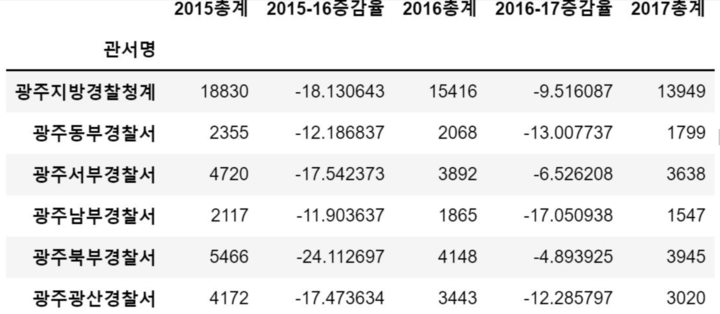


In [119]:
df_2015 = pd.read_csv('./data/2015.csv', index_col='관서명', encoding='euc-kr')
df_2016 = pd.read_csv('./data/2016.csv', index_col='관서명', encoding='euc-kr')
df_2017 = pd.read_csv('./data/2017.csv', index_col='관서명', encoding='euc-kr')

In [103]:
df_2015.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   관서명      36 non-null     object
 1   구분       36 non-null     object
 2   살인       36 non-null     int64 
 3   강도       36 non-null     int64 
 4   강간·강제추행  36 non-null     int64 
 5   절도       36 non-null     int64 
 6   폭력       36 non-null     int64 
dtypes: int64(5), object(2)
memory usage: 2.1+ KB


In [152]:
df_2016

,구분,살인,강도,강간·강제추행,절도,폭력
관서명,,,,,,
광주지방경찰청계,발생건수,17,47,701,6052,8599
광주지방경찰청계,검거건수,18,47,713,4242,7631
광주지방경찰청계,검거인원,21,54,758,3455,10747
광주지방경찰청계,구속,14,25,37,132,57
광주지방경찰청계,불구속,3,25,491,2862,5267
광주지방경찰청계,기타,4,4,230,461,5423
광주동부경찰서,발생건수,3,8,83,832,1142
광주동부경찰서,검거건수,3,7,70,679,1002
광주동부경찰서,검거인원,4,10,71,543,1497


In [173]:
df_2015[df_2015['구분'] == '발생건수'].loc[:,'살인':].sum(axis=1)

관서명
광주지방경찰청계    18830
광주동부경찰서      2355
광주서부경찰서      4720
광주남부경찰서      2117
광주북부경찰서      5466
광주광산경찰서      4172
dtype: int64

In [174]:
df_2015_sum= df_2015[df_2015['구분'] == '발생건수'].loc[:,'살인':].sum(axis=1)
df_2016_sum = df_2016[df_2016['구분'] == '발생건수'].loc[:,'살인':].sum(axis=1)
df_2017_sum = df_2017[df_2017['구분'] == '발생건수'].loc[:,'살인':].sum(axis=1)

In [178]:
df_2015_16 = (df_2016_sum - df_2015_sum) / df_2015_sum * 100
df_2016_17 = (df_2017_sum - df_2016_sum) / df_2016_sum * 100

In [179]:
df_total = pd.concat([df_2015_sum, df_2015_16, df_2016_sum, df_2016_17, df_2017_sum],axis=1)
df_total.columns = ['2015총계','2015-16증감율', '2016총계','2016-17증감율', '2017총계']

In [181]:
df_total.drop('광주지방경찰청', axis=0)

,2015총계,2015-16증감율,2016총계,2016-17증감율,2017총계
관서명,,,,,
광주지방경찰청계,18830.0,-18.130643,15416.0,-9.516087,13949
광주동부경찰서,2355.0,-12.186837,2068.0,-13.007737,1799
광주서부경찰서,4720.0,-17.542373,3892.0,-6.526208,3638
광주남부경찰서,2117.0,-11.903637,1865.0,-17.050938,1547
광주북부경찰서,5466.0,-24.112697,4148.0,-4.893925,3945
광주광산경찰서,4172.0,-17.473634,3443.0,-12.285797,3020


In [8]:
import requests

# 1. 데이터 요청 및 응답
response = requests.get('https://www.naver.com')
print(response) # 응답 코드 확인
#print(response.text)
print(type(response.text))

# 2. 응답 데이터(str)를 html로 형변환 -> parsing
from bs4 import BeautifulSoup as bs
soup = bs(response.text, 'lxml')
print(type(soup))
print(soup)

# 3. html에서 원하는 데이터 추출
li_tags = soup.select('li')
print(type(li_tags))
print(li_tags)

<Response [200]>
<class 'str'>
<class 'bs4.BeautifulSoup'>
<!DOCTYPE html>
<html class="fzoom" lang="ko"> <head> <meta charset="utf-8"/> <meta content="origin" name="Referrer"/> <meta content="IE=edge" http-equiv="X-UA-Compatible"/> <meta content="width=1190" name="viewport"/> <title>NAVER</title> <meta content="NAVER" name="apple-mobile-web-app-title"/> <meta content="index,nofollow" name="robots"/> <meta content="네이버 메인에서 다양한 정보와 유용한 컨텐츠를 만나 보세요" name="description"/> <meta content="네이버" property="og:title"/> <meta content="https://www.naver.com/" property="og:url"/> <meta content="https://s.pstatic.net/static/www/mobile/edit/2016/0705/mobile_212852414260.png" property="og:image"/> <meta content="네이버 메인에서 다양한 정보와 유용한 컨텐츠를 만나 보세요" property="og:description"/> <meta content="summary" name="twitter:card"/> <meta content="" name="twitter:title"/> <meta content="https://www.naver.com/" name="twitter:url"/> <meta content="https://s.pstatic.net/static/www/mobile/edit/2016/0705/mobile_21285241

In [13]:
import requests
from bs4 import BeautifulSoup as bs

url = 'https://api.musinsa.com/api2/dp/v1/plp/goods?gf=A&sortCode=POPULAR&category=001&size=60&testGroup=&caller=CATEGORY&page=1&seen=0&seenAds='

headers = {'user-agent':'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/143.0.0.0 Safari/537.36'}
response = requests.get(url, headers=headers)
data = response.json()
data['data']

{'list': [{'goodsNo': 5862132,
   'goodsName': '압도×블랙컴뱃 올라운더 반소매 티셔츠',
   'goodsLinkUrl': 'https://www.musinsa.com/products/5862132',
   'thumbnail': 'https://image.msscdn.net/images/goods_img/20251230/5862132/5862132_17673316311774_500.png',
   'displayGenderText': '남성',
   'isSoldOut': False,
   'normalPrice': 64000,
   'price': 64000,
   'couponPrice': None,
   'saleRate': 0,
   'couponSaleRate': None,
   'hasOptionPrice': False,
   'brand': 'overwhelm',
   'brandName': '압도',
   'brandLinkUrl': 'https://www.musinsa.com/brand/overwhelm',
   'reviewCount': 2,
   'reviewScore': 80,
   'isOptionVisible': True,
   'isAd': False,
   'adTooltip': None,
   'plusDeliveryGuideText': '',
   'infoLabelList': [],
   'imageLabelList': [],
   'clickTrackers': [],
   'impressionTrackers': [],
   'snap': None,
   'score': 0.0,
   'isPlusDelivery': False,
   'usedConditionGrade': None},
  {'goodsNo': 5837315,
   'goodsName': '바라클라바 와플 풀오버 후디_블랙',
   'goodsLinkUrl': 'https://www.musinsa.com/products/5

In [19]:
%%writefile 03_visualization/my_web/basic_practice2.py

import streamlit as st
import pandas as pd
import time

st.title('나만의 대시보드')
st.header('실습 예제 작성')


st.write('이 대시보드는 Streamlit을 활용하여 만들어졌습니다.')

st.markdown('이곳에서는 다양한 *Streamlit* 함수를 활용할 수 있습니다. [여기](https://www.naver.com)를 클릭해보세요')

st.markdown('---')

df = pd.DataFrame({
    '상품':['A', 'B', 'C', 'D'],
    '판매량':[100, 150, 1200, 50],
    '작년대비 증감비':["+10%", "+5%", '+7%', '-15%']
})


#df
#st.dataframe(df)
st.table(df)

# metric
max_row = df.loc[df['판매량'].idxmax()]
max_sales = int(max_row['판매량'])
max_delta = str(max_row['작년대비 증감비'])


# 2. value와 delta를 각각 metric 메소드에 전달
st.metric('최대 판매량', max_sales, max_delta)

# selectbox
selected = st.selectbox('어떤 상품의 정보를 보시겠습니까?', options=df['상품'], index=0)
selected_sales = int(df.loc[df['상품'] == selected, '판매량'])

st.write(f'{selected}의 판매량은 {selected_sales}입니다.')

st.markdown("---")
st.header('햄스터')

st.image('../../data/hamster.jpg', width=200, caption='Cute')

st.warning('이 텍스트는 경고용')

st.markdown('---')

if st.button('성공 버튼'):
    st.balloons()
    st.success('성공입니다.')
    
    
st.markdown('---')
name = st.text_input('이름을 입력하세요:')
st.write(f'안녕하세요, {name}님!')

# 진행버튼

if st.button('진행버튼', key='p_btn'):
    progress_bar = st.progress(0)
    
    for x in range(0, 101, 10):
        progress_bar.progress(x)
        time.sleep(1)

Overwriting 03_visualization/my_web/basic_practice2.py
